# Evaluating EDGE in finite samples

This Julia notebook follows the same experiment, equations, sample sizes, parameters, and decision rules as its Python counterpart. Random experiments use the displayed integer seeds with Julia’s `Xoshiro` generator, so their realized samples differ from NumPy. Public observations use the same stated data sources. Figures use the requested dark theme, and Julia outputs are saved under `outputs/julia`. The finite-sample study draws its 1,440 child seeds from `Xoshiro(20260926)` and saves every Gaussian innovation, observed trade side, and resulting OHLC bar so the calculation can be repeated. The published equation is compared with the current library calculation.

An observed log price is written as an unobserved fair log price plus bid-ask movement, while the indicator marks whether a bar contains a price change:

$$
p_t=\widetilde p_t+Z_t,
\qquad
\tau_t=
\begin{cases}
0,&h_t=l_t=c_{t-1},\\
1,&\text{otherwise}.
\end{cases}
$$

Here, $p_t$ is an observed log price; $\widetilde p_t$ is its unobserved fair component; $Z_t$ is bid-ask movement. $h_t,l_t,c_{t-1}$ are the high, low, and previous close log prices; $\tau_t$ is zero for a flat or forward-filled bar and one otherwise.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("11_market_microstructure");
using CSV, Printf
using RiskLabAI.Features: alpha_estimates,bekker_parkinson_volatility_estimates,beta_estimates,corwin_schultz_estimator,edge_estimator,gamma_estimates,sigma_estimates
raw = load_binance()
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
minute = select(raw,:time,"Open"=>:open,"High"=>:high,"Low"=>:low,:close,:volume,:quote_volume,:trades)

function make_bars(period)
    return combine(groupby(transform(minute,:time=>(time->floor.(time,period))=>:time),:time;sort=true),:open=>first=>:open,:high=>maximum=>:high,:low=>minimum=>:low,:close=>last=>:close,:volume=>sum=>:volume,:quote_volume=>sum=>:quote_volume,:trades=>sum=>:trades)
end

function rolling_mean(values,window)
    result = fill(NaN,length(values))
    for ending in window:length(values)
        sample = values[ending-window+1:ending]
        all(isfinite,sample) && (result[ending]=mean(sample))
    end
    return result
end

function calendar_ticks(times;step=Day(6))
    ticks = collect(DateTime(Date(first(times))):step:DateTime(Date(last(times))))
    return Dates.value.(ticks),Dates.format.(ticks,dateformat"mm-dd")
end

function spread_values(sample)
    magnitude = edge_estimator(sample.open,sample.high,sample.low,sample.close)
    signed = edge_estimator(sample.open,sample.high,sample.low,sample.close;sign=true)
    cs = mean(filter(isfinite,corwin_schultz_estimator(sample.high,sample.low,1)))
    return (magnitude=magnitude,zero_floor=max(signed,0.),signed=signed,cs=cs)
end

bars_15 = make_bars(Minute(15));


## Efficient Combination of Two Measurements

EDGE gives more weight to the squared-spread measurement with lower variance, then converts the combined squared estimate to a spread:

$$
\widehat S_{\mathrm{EDGE}}^{2}
=\frac{v_2e_1+v_1e_2}{v_1+v_2},
\qquad
\widehat S_{\mathrm{mag}}=\sqrt{\left|\widehat S_{\mathrm{EDGE}}^{2}\right|},
\qquad
\widehat S_{0}=\sqrt{\max\!\left\{0,\widehat S_{\mathrm{EDGE}}^{2}\right\}}.
$$

Here, $e_1,e_2$ are the sample means of two squared-spread measurements; $v_1,v_2$ are their sample variances. $\widehat S_{\mathrm{EDGE}}^{2}$ is the combined squared estimate; $\widehat S_{\mathrm{mag}}$ is the public library's magnitude form; $\widehat S_0$ floors a negative squared estimate at zero.

Row,Estimator,Windows,"Mean, basis points","Median, basis points","Standard deviation, basis points","10th percentile, basis points","90th percentile, basis points",Nonpositive share
,String,Int64,Float64,Float64,Float64,Float64,Float64,Float64
1,EDGE magnitude,721,2.623,2.2954,1.51047,1.01511,4.53741,0.0
2,EDGE zero floor,721,1.26798,0.0,1.97994,0.0,4.25483,0.600555
3,EDGE signed,721,-0.0870363,-1.35341,3.02714,-3.32518,4.25483,0.600555
4,Corwin-Schultz average,721,28.8034,26.6865,10.2803,19.564,40.2422,0.0


Row,Window bars,Windows,"EDGE median, basis points","EDGE zero-floor median, basis points","Corwin-Schultz median, basis points",Negative squared EDGE share
,Int64,Int64,Float64,Float64,Float64,Float64
1,24,493,2.61486,0.0,25.2436,0.565923
2,48,245,2.40053,0.0,25.8424,0.542857
3,96,121,2.28499,0.0,26.8646,0.61157
4,192,59,2.31756,0.0,27.451,0.610169
5,384,28,2.01706,0.0,28.3183,0.535714


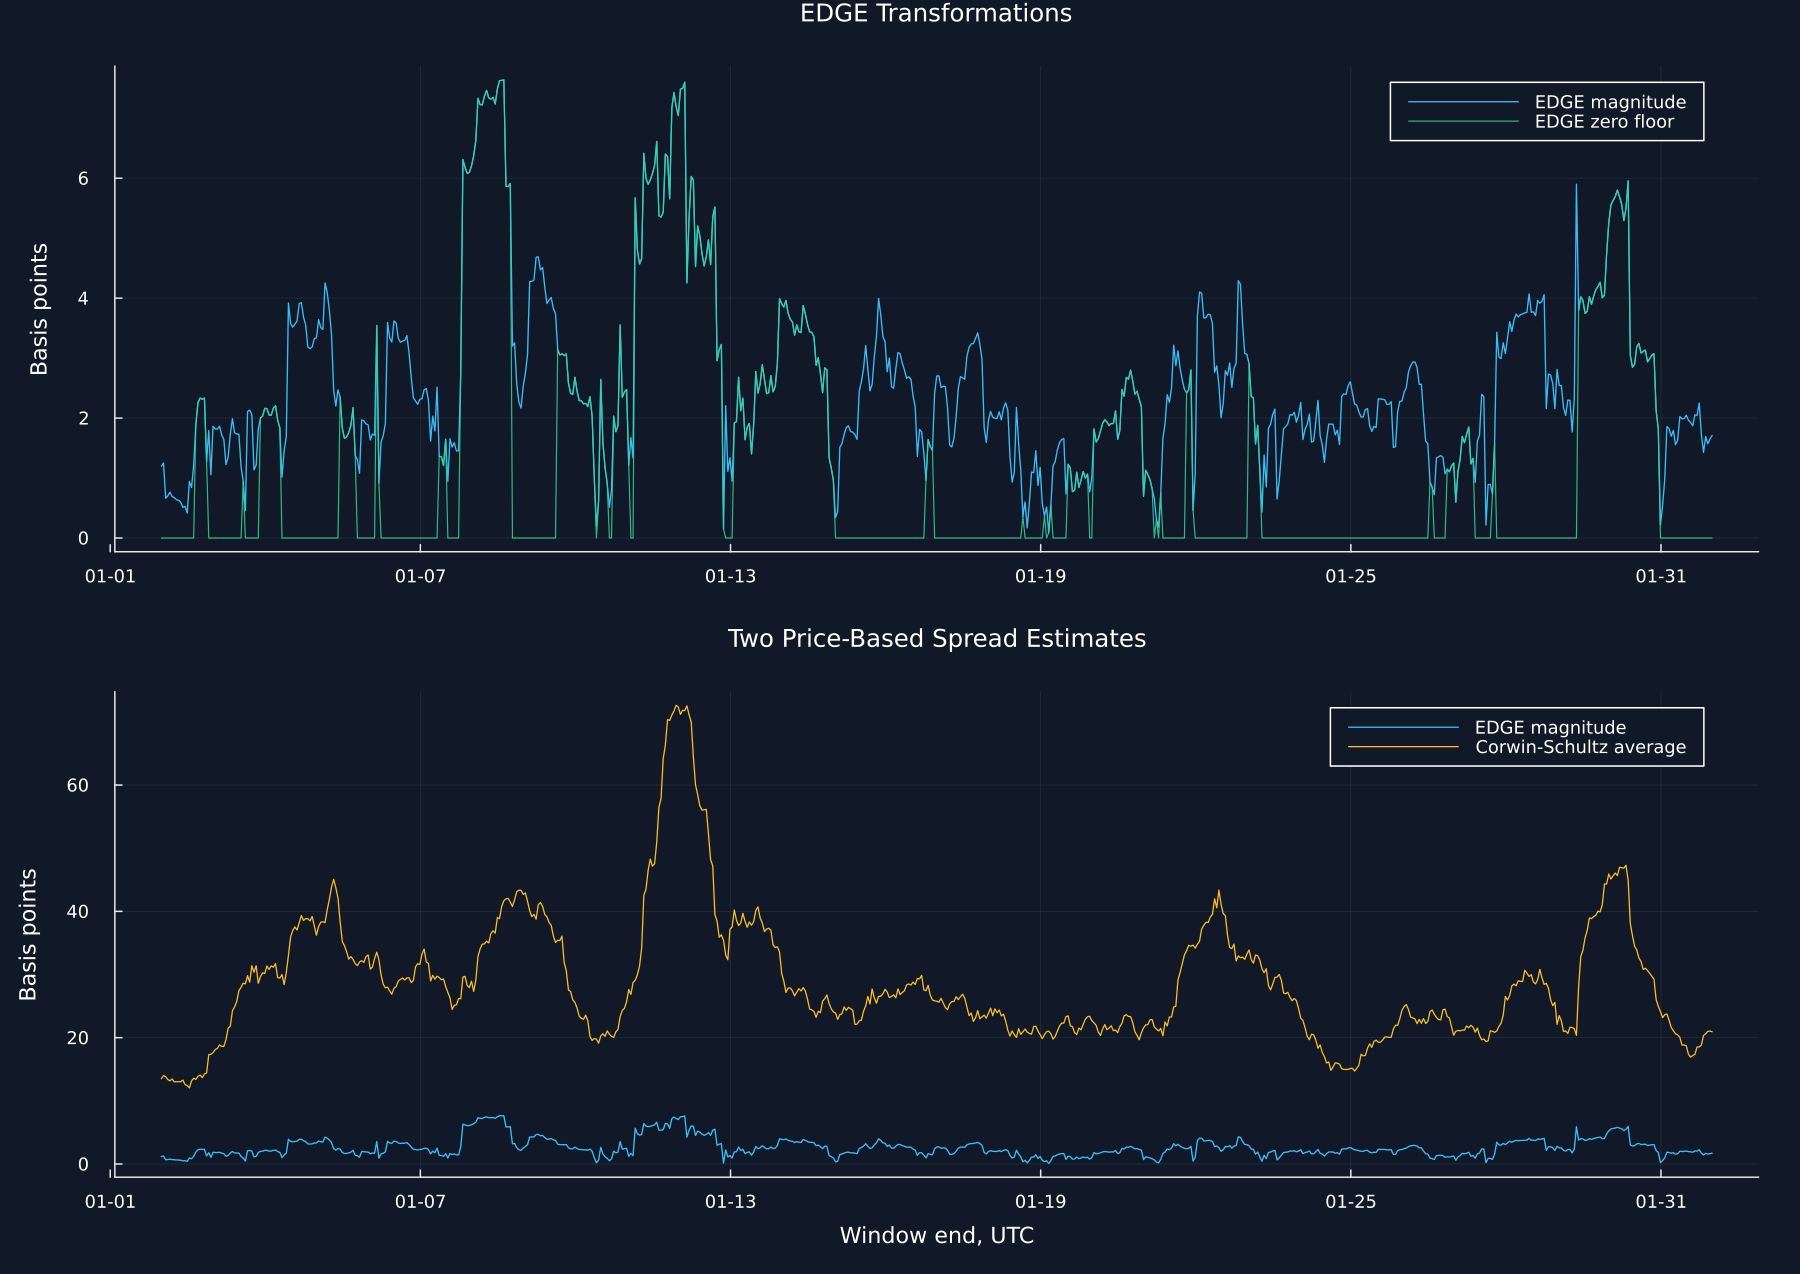

In [2]:
rolling_window = 96
rolling_step = 4
public_rows = NamedTuple[]
for endpoint in rolling_window:rolling_step:nrow(bars_15)
    sample = bars_15[endpoint-rolling_window+1:endpoint,:]
    values = spread_values(sample)
    push!(public_rows,(time=sample.time[end],magnitude=values.magnitude,zero=values.zero_floor,signed=values.signed,cs=values.cs))
end
public_estimates = DataFrame(public_rows)
rename!(public_estimates,["Time","EDGE magnitude","EDGE zero floor","EDGE signed","Corwin-Schultz average"])
public_summary_rows = NamedTuple[]
for name in names(public_estimates)[2:end]
    values = public_estimates[!,name]
    available = filter(isfinite,values)
    push!(public_summary_rows,(name=name,windows=length(available),average=10000mean(available),median=10000median(available),deviation=10000std(available),lower=10000quantile(available,.1),upper=10000quantile(available,.9),nonpositive=mean(values.<=0)))
end
edge_public_summary = DataFrame(public_summary_rows)
rename!(edge_public_summary,["Estimator","Windows","Mean, basis points","Median, basis points","Standard deviation, basis points","10th percentile, basis points","90th percentile, basis points","Nonpositive share"])
save_table(edge_public_summary,paths,"edge_public_summary";caption="Public rolling spread estimates from 96 fifteen-minute bars.",label="tab:chapter10-edge-public-summary")
public_sensitivity_rows = NamedTuple[]
edge_sensitivity_paths = NamedTuple[]
for current_window in [24,48,96,192,384]
    values = NamedTuple[]
    current_step = max(4,current_window÷4)
    for endpoint in current_window:current_step:nrow(bars_15)
        sample = bars_15[endpoint-current_window+1:endpoint,:]
        estimate = spread_values(sample)
        push!(values,estimate)
        push!(edge_sensitivity_paths,(window=current_window,endpoint=endpoint,time=sample.time[end],magnitude=estimate.magnitude,zero_floor=estimate.zero_floor,signed=estimate.signed,cs=estimate.cs))
    end
    push!(public_sensitivity_rows,(window=current_window,windows=count(isfinite,getproperty.(values,:magnitude)),magnitude=10000median(getproperty.(values,:magnitude)),zero_floor=10000median(getproperty.(values,:zero_floor)),cs=10000median(getproperty.(values,:cs)),negative=mean(getproperty.(values,:signed).<0)))
end
edge_window_sensitivity = DataFrame(public_sensitivity_rows)
rename!(edge_window_sensitivity,["Window bars","Windows","EDGE median, basis points","EDGE zero-floor median, basis points","Corwin-Schultz median, basis points","Negative squared EDGE share"])
save_table(edge_window_sensitivity,paths,"edge_window_sensitivity";caption="Public spread estimates across rolling window lengths.",label="tab:chapter10-edge-window-sensitivity")
p1 = plot(public_estimates.Time,10000public_estimates[!,"EDGE magnitude"];color=palette.cyan,linewidth=.9,label="EDGE magnitude",title="EDGE Transformations",ylabel="Basis points",xticks=calendar_ticks(public_estimates.Time),legend=:topright)
plot!(p1,public_estimates.Time,10000public_estimates[!,"EDGE zero floor"];color=palette.green,linewidth=.8,alpha=.85,label="EDGE zero floor")
p2 = plot(public_estimates.Time,10000public_estimates[!,"EDGE magnitude"];color=palette.cyan,linewidth=.9,label="EDGE magnitude",title="Two Price-Based Spread Estimates",xlabel="Window end, UTC",ylabel="Basis points",xticks=calendar_ticks(public_estimates.Time),legend=:topright)
plot!(p2,public_estimates.Time,10000public_estimates[!,"Corwin-Schultz average"];color=palette.amber,linewidth=.85,label="Corwin-Schultz average")
save_figure(plot(p1,p2;layout=(2,1),size=(1200,850),left_margin=6Plots.mm),paths,"public_edge_comparison")
save_data(public_estimates,paths,"public_edge_estimates");
save_data(DataFrame(edge_sensitivity_paths),paths,"edge_sensitivity_paths");


## Known-Truth Finite-Sample Comparison

Bias measures average signed error, while root mean squared error measures the typical error size and gives extra weight to large errors:

$$
\operatorname{Bias}(\widehat S)
=\frac{1}{B}\sum_{b=1}^{B}(\widehat S_b-S_0),
\qquad
\operatorname{RMSE}(\widehat S)
=\sqrt{\frac{1}{B}\sum_{b=1}^{B}(\widehat S_b-S_0)^2}.
$$

Here, $\widehat S_b$ is the spread estimate in repetition $b$; $S_0$ is the known spread used to generate prices. $B$ is the number of repetitions; $\operatorname{Bias}$ is signed average error; $\operatorname{RMSE}$ is the square root of average squared error.

Row,Item,Value
,String,String
1,Bars per repetition,42
2,Trade opportunities per bar,60
3,Bar volatility,0.0200
4,True spreads,"0.0025, 0.0050, 0.0100, 0.0200"
5,Expected trades per bar,"3, 12, 60"
6,Repetitions per setting,120
7,Total generated price samples,1440


Row,"True spread, basis points",Expected trades per bar,Estimator,Valid repetitions,"Mean estimate, basis points","Bias, basis points","RMSE, basis points","Standard deviation, basis points"
,Float64,Int64,String,Int64,Float64,Float64,Float64,Float64
1,100.0,3,Corwin-Schultz,120,13.2247,-86.7753,86.9687,5.8221
2,100.0,3,EDGE magnitude,120,105.574,5.57404,46.6913,46.5517
3,100.0,3,EDGE zero floor,120,96.7894,-3.21061,57.7564,57.9088
4,100.0,12,Corwin-Schultz,120,68.9488,-31.0512,33.9903,13.8841
5,100.0,12,EDGE magnitude,120,97.0452,-2.95475,31.3948,31.3865
6,100.0,12,EDGE zero floor,120,95.3544,-4.64556,35.0747,34.9115
7,100.0,60,Corwin-Schultz,120,120.079,20.0791,26.9419,18.039
8,100.0,60,EDGE magnitude,120,100.102,0.102469,18.0989,18.1745
9,100.0,60,EDGE zero floor,120,100.102,0.102469,18.0989,18.1745


Row,Estimator,"Mean absolute bias, basis points","Mean RMSE, basis points",Lowest RMSE settings,Compared settings
,String,Float64,Float64,Int64,Int64
1,EDGE magnitude,11.96,32.5855,8,12
2,EDGE zero floor,4.42873,34.8339,0,12
3,Corwin-Schultz,47.2357,50.9338,4,12


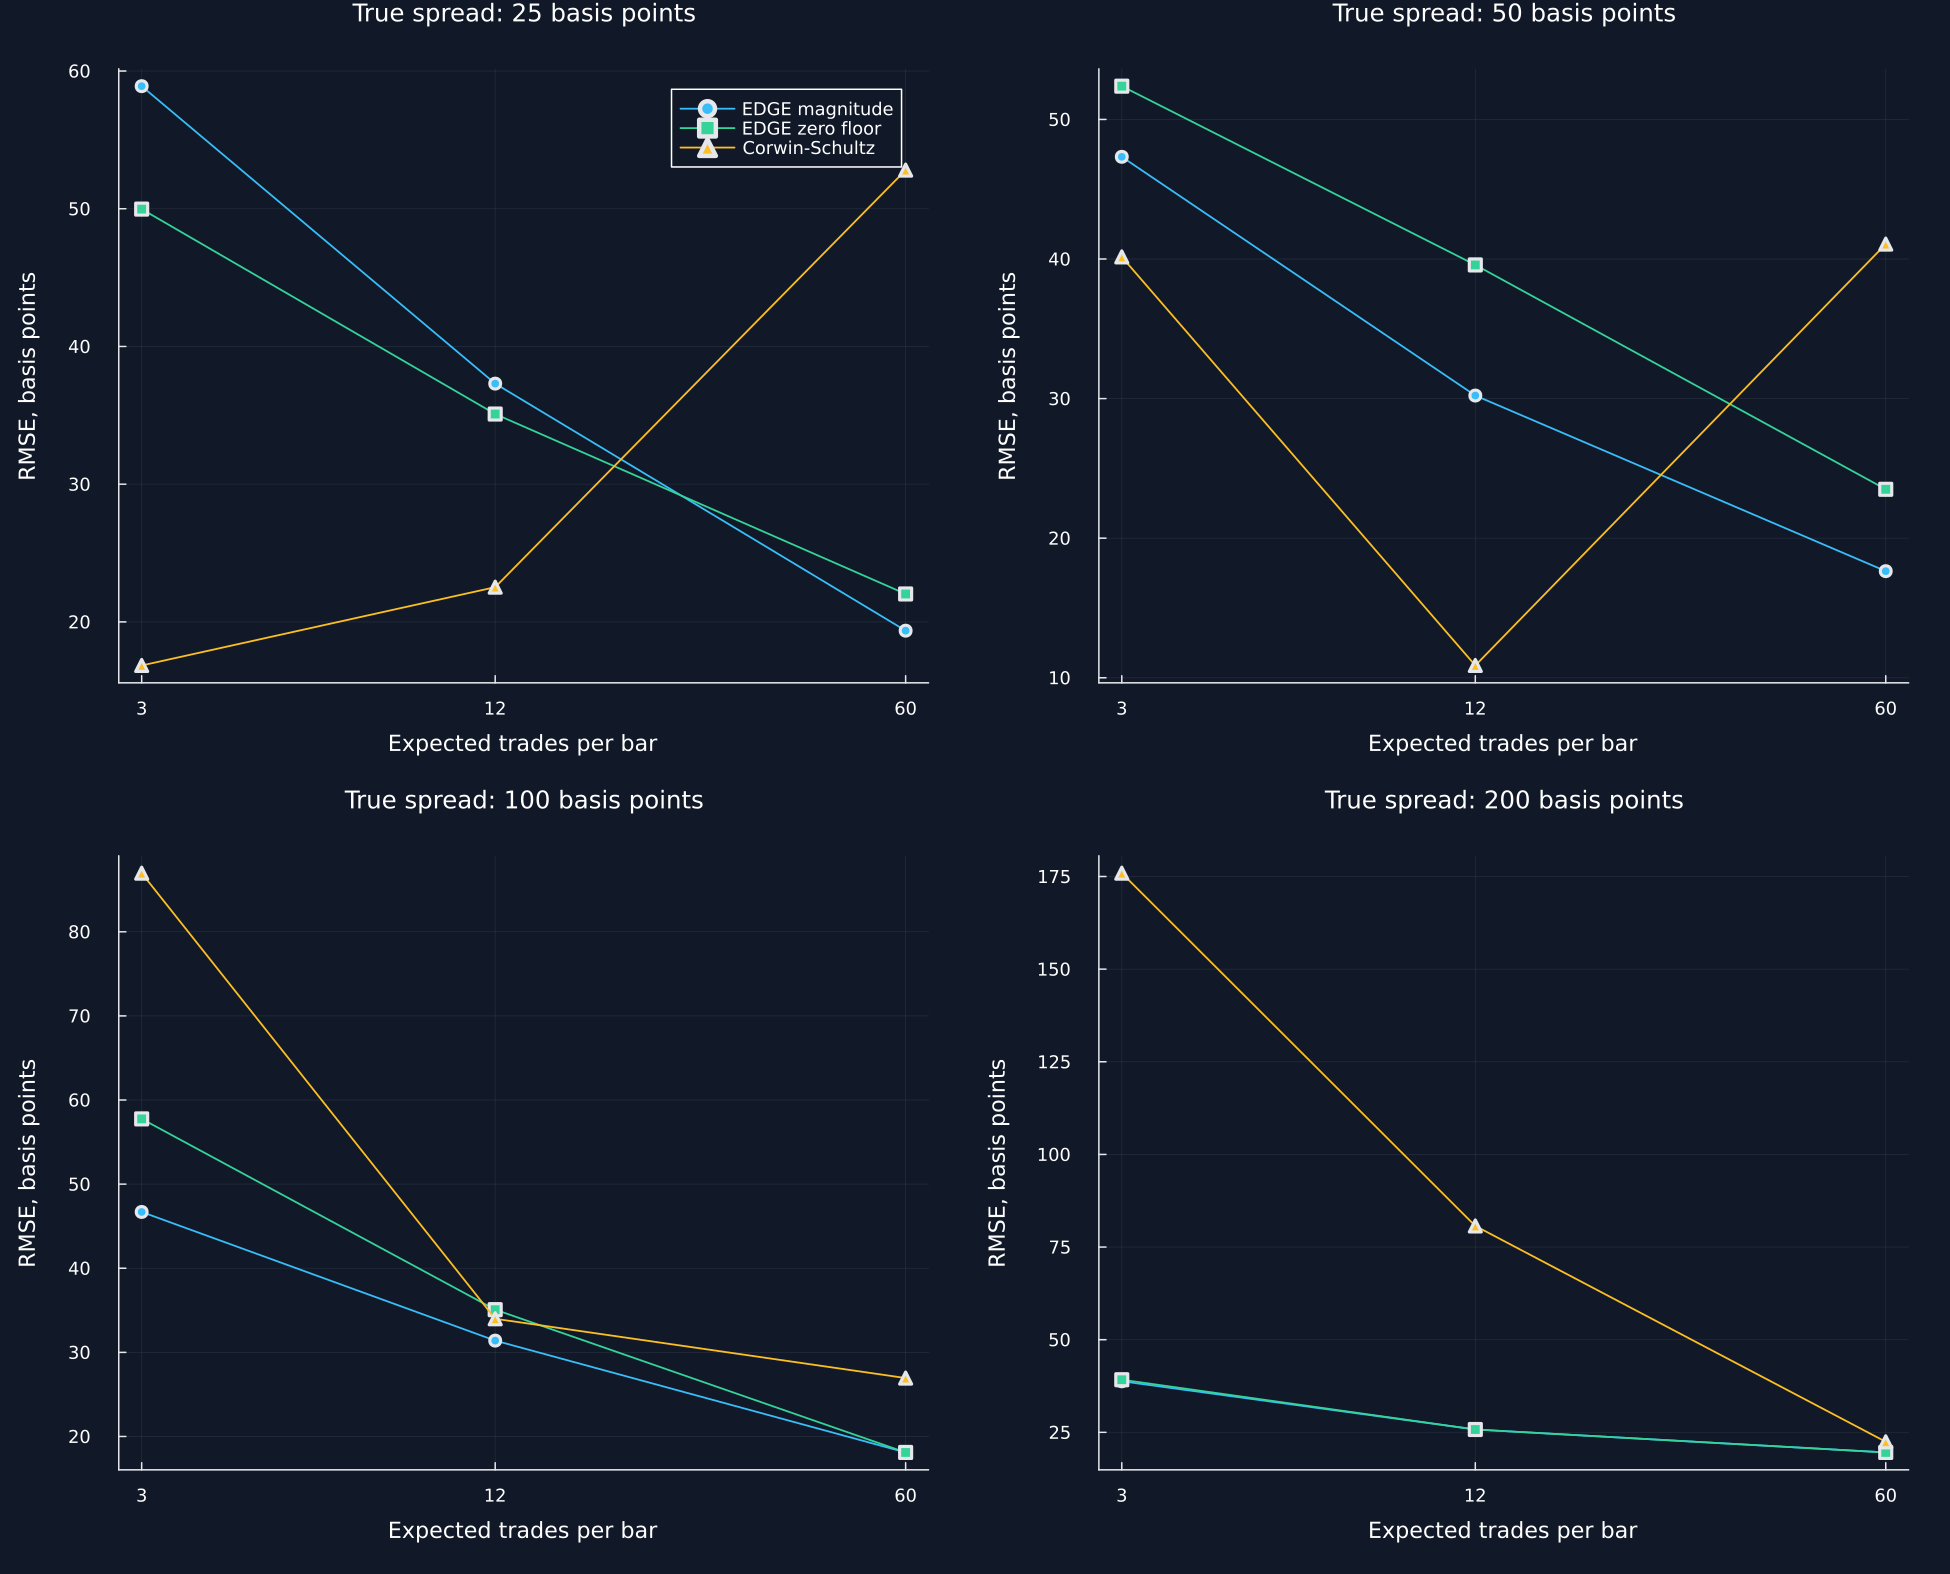

In [3]:
function simulate_ohlc(seed,true_spread,expected_trades,normal_draws,trade_codes,run;bars=42,opportunities=60,bar_volatility=.02)
    rng = Xoshiro(seed)
    latent_price,previous_close = 100.,100.
    result = Matrix{Float64}(undef,bars,4)
    observation_probability = min(expected_trades/opportunities,1.)
    step_volatility = bar_volatility/sqrt(opportunities)
    for bar in 1:bars
        row = (run-1)*bars+bar
        normals = randn(rng,opportunities)
        increments = -.5step_volatility^2 .+step_volatility.*normals
        latent_path = latent_price.*exp.(cumsum(increments))
        observed = rand(rng,opportunities).<observation_probability
        normal_draws[row,:] = normals
        if any(observed)
            sides = rand(rng,[-1,1],sum(observed))
            trade_codes[row,observed] = sides
            transactions = latent_path[observed].*(1 .+sides.*true_spread./2)
            result[bar,:] = [first(transactions),maximum(transactions),minimum(transactions),last(transactions)]
        else
            result[bar,:] .= previous_close
        end
        latent_price = last(latent_path)
        previous_close = result[bar,4]
    end
    return DataFrame(result,[:open,:high,:low,:close])
end

true_spreads = [.0025,.005,.01,.02]
expected_trade_counts = [3,12,60]
repetitions = 120
sample_count = length(true_spreads)*length(expected_trade_counts)*repetitions
child_seeds = rand(Xoshiro(20260926),UInt64,sample_count)
normal_draws = Matrix{Float64}(undef,sample_count*42,60)
trade_codes = zeros(Int8,sample_count*42,60)
simulation_rows = NamedTuple[]
design_rows = NamedTuple[]
ohlc_paths = DataFrame()
run = 0
for true_spread in true_spreads,expected_trades in expected_trade_counts,repetition in 0:repetitions-1
    run += 1
    sample = simulate_ohlc(child_seeds[run],true_spread,expected_trades,normal_draws,trade_codes,run)
    values = spread_values(sample)
    push!(design_rows,(run=run,seed=string(child_seeds[run]),true_spread=true_spread,expected_trades=expected_trades,repetition=repetition))
    append!(ohlc_paths,hcat(DataFrame(run=fill(run,42),bar=1:42),sample);cols=:union)
    for (method,estimate) in [("EDGE magnitude",values.magnitude),("EDGE zero floor",values.zero_floor),("Corwin-Schultz",values.cs)]
        push!(simulation_rows,(true_spread=true_spread,trades=expected_trades,repetition=repetition,method=method,estimate=estimate))
    end
end
simulation_results = DataFrame(simulation_rows)
rename!(simulation_results,["True spread","Expected trades per bar","Repetition","Estimator","Estimate"])
grouped_rows = NamedTuple[]
for group in groupby(simulation_results,["True spread","Expected trades per bar","Estimator"];sort=true)
    truth = group[1,"True spread"]
    errors = group.Estimate.-truth
    push!(grouped_rows,(truth=truth,trades=group[1,"Expected trades per bar"],method=group.Estimator[1],valid=nrow(group),average=mean(group.Estimate),bias=mean(errors),rmse=sqrt(mean(errors.^2)),deviation=std(group.Estimate)))
end
simulation_summary = DataFrame(grouped_rows)
rename!(simulation_summary,["True spread","Expected trades per bar","Estimator","Valid repetitions","Mean estimate","Bias","RMSE","Standard deviation"])
simulation_design = DataFrame("Item"=>["Bars per repetition","Trade opportunities per bar","Bar volatility","True spreads","Expected trades per bar","Repetitions per setting","Total generated price samples"],"Value"=>["42","60","0.0200","0.0025, 0.0050, 0.0100, 0.0200","3, 12, 60",string(repetitions),string(sample_count)])
save_table(simulation_design,paths,"simulation_design";caption="Known-truth spread simulation design.",label="tab:chapter10-simulation-design")
finite_sample_comparison = copy(simulation_summary[simulation_summary[!,"True spread"].==.01,:])
for name in ["True spread","Mean estimate","Bias","RMSE","Standard deviation"]
    finite_sample_comparison[!,name] .*= 10000
    rename!(finite_sample_comparison,name=>name*", basis points")
end
save_table(finite_sample_comparison,paths,"finite_sample_comparison";caption="Finite-sample results when the known spread is 100 basis points.",label="tab:chapter10-finite-sample-comparison")
best_methods = [group.Estimator[argmin(group.RMSE)] for group in groupby(simulation_summary,["True spread","Expected trades per bar"];sort=true)]
ranking_rows = NamedTuple[]
for group in groupby(simulation_summary,:Estimator;sort=true)
    method = first(group.Estimator)
    push!(ranking_rows,(method=method,bias=10000mean(abs.(group.Bias)),rmse=10000mean(group.RMSE),best=count(==(method),best_methods),settings=nrow(group)))
end
estimator_ranking = sort!(DataFrame(ranking_rows),:rmse)
rename!(estimator_ranking,["Estimator","Mean absolute bias, basis points","Mean RMSE, basis points","Lowest RMSE settings","Compared settings"])
save_table(estimator_ranking,paths,"estimator_ranking";caption="Summary across all known spreads and trading frequencies.",label="tab:chapter10-estimator-ranking")
panels = Plots.Plot[]
for (index,truth) in enumerate(true_spreads)
    panel = plot(title="True spread: $(Int(10000truth)) basis points",xlabel="Expected trades per bar",ylabel="RMSE, basis points",xscale=:log10,xticks=(expected_trade_counts,string.(expected_trade_counts)),legend=index==1 ? :topright : false)
    for (method,color,marker) in [("EDGE magnitude",palette.cyan,:circle),("EDGE zero floor",palette.green,:square),("Corwin-Schultz",palette.amber,:utriangle)]
        selected = (simulation_summary[!,"True spread"].==truth).&(simulation_summary.Estimator.==method)
        line = sort(simulation_summary[selected,:],"Expected trades per bar")
        plot!(panel,line[!,"Expected trades per bar"],10000line.RMSE;color=color,marker=marker,linewidth=1.2,label=method)
    end
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(2,2),size=(1300,1050),left_margin=6Plots.mm),paths,"finite_sample_spread_comparison")
save_data(simulation_results,paths,"spread_simulation_results");
save_data(simulation_summary,paths,"spread_simulation_summary");
save_data(DataFrame(design_rows),paths,"spread_simulation_seeds");
save_data(ohlc_paths,paths,"spread_simulation_ohlc");
primitive_index = DataFrame(run=repeat(1:sample_count;inner=42),bar=repeat(1:42;outer=sample_count))
save_data(hcat(primitive_index,DataFrame(normal_draws,["z$i" for i in 1:60])),paths,"spread_simulation_normals");
save_data(hcat(primitive_index,DataFrame(trade_codes,["side$i" for i in 1:60])),paths,"spread_simulation_trade_codes");


## Tests

In [4]:
@assert nrow(public_estimates)==721
@assert all(isfinite,Matrix(public_estimates[:,2:end]))
@assert public_estimates[!,"EDGE magnitude"]≈abs.(public_estimates[!,"EDGE signed"])
@assert public_estimates[!,"EDGE zero floor"]≈max.(public_estimates[!,"EDGE signed"],0)
@assert all(public_estimates[!,"EDGE magnitude"].>=0)
@assert all(public_estimates[!,"EDGE zero floor"].>=0)
@assert all(public_estimates[!,"Corwin-Schultz average"].>=0)
@assert edge_window_sensitivity[!,"Window bars"]==[24,48,96,192,384]
@assert all(0 .<=edge_window_sensitivity[!,"Negative squared EDGE share"].<=1)
@assert nrow(simulation_results)==length(true_spreads)*length(expected_trade_counts)*repetitions*3
@assert nrow(simulation_summary)==length(true_spreads)*length(expected_trade_counts)*3
@assert all(simulation_summary[!,"Valid repetitions"].==repetitions)
@assert all(isfinite,simulation_results.Estimate)
@assert all(Matrix(simulation_summary[:,["Mean estimate","RMSE","Standard deviation"]]).>=0)
@assert nrow(finite_sample_comparison)==length(expected_trade_counts)*3
@assert all(estimator_ranking[!,"Compared settings"].==length(true_spreads)*length(expected_trade_counts))
@assert sum(estimator_ranking[!,"Lowest RMSE settings"])==length(true_spreads)*length(expected_trade_counts)
@assert isfile(joinpath(paths.figures,"public_edge_comparison.pdf"))
@assert isfile(joinpath(paths.figures,"finite_sample_spread_comparison.pdf"))
@assert isfile(joinpath(paths.tables,"edge_public_summary.tex"))
@assert isfile(joinpath(paths.tables,"edge_window_sensitivity.tex"))
@assert isfile(joinpath(paths.tables,"simulation_design.tex"))
@assert isfile(joinpath(paths.tables,"finite_sample_comparison.tex"))
@assert isfile(joinpath(paths.tables,"estimator_ranking.tex"))
